# CSForge — Example design

**Author:** [David Gerard](https://profiles.ucl.ac.uk/95497-david-gerard)
**Based on:** [PhotonForge Documentation - Cascaded Rings Filter](https://www.flexcompute.com/photonforge/doc/)

## Overview



In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import tidy3d as td

from cornerstone_forge import si_220nm_passive as pdk
import photonforge as pf

# Build the technology and set it globally
tech = pdk.csforge_si_220nm_pdk(include_substrate=True, sidewall_angle_si=0.0)
pf.config.default_technology = tech

# Guardrail: cells gated by `run_fdtd` submit simulations to the Tidy3D cloud and
# consume FlexCredits. Set to True to run them.
run_fdtd = False

Output()

Fitting range: 1.200 um to 1.697 um


Output()

18:47:24 BST WARNING: Did not finish enforcing passivity in dispersion fitter.  
             If the fit is not good enough, consider increasing                 
             'AdvancedFastFitterParam.passivity_num_iters'.                     

In [2]:
wavelengths = np.linspace(1.548, 1.552, 81)
port_spec = tech.ports["strip_1550nm"]

## Point Couplers

Instead of solving the full cascaded problem in FDTD, we can solve for the two point couplers (i.e. coupling between the bus waveguide to ring waveguide and coupling between two ring waveguides).
Then, we will be able to utilize the computed [S matrix](../guides/S_Parameters.ipynb) to dynamically vary the number of rings and run fast [circuit simulations](../guides/Circuit_Model.ipynb).

We use [parametric components](../guides/Parametric_Component_Library.ipynb) to quickly design both couplers:
- [ring_coupler](../_autosummary/photonforge.parametric.ring_coupler.rst) for the bus, and
- [dual_ring_coupler](../_autosummary/photonforge.parametric.dual_ring_coupler.rst) for the inter-ring coupling.

Note that we decrease the default mesh refinement from 20 to 15 minimal grid cells per wavelength to decrease the simulation size.
That can slightly change the exact resonant frequencies of the filter, but fabrication imperfections usually have a much higher impact here, so that is not so important in this example.

However, we define a smaller shut-off condition (10⁻⁷, instead of the default 10⁻⁵) to decrease residual fields in the simulation, and we increase the default run time quality factor to ensure enough time for the shut-off condition.
These measures are necessary because we will combine the frequency-domain S parameters into resonant devices, where small numerical errors can be amplified and lead to non-passive responses (identifiable, for example, if we see any S parameter magnitude above unit).

In [3]:
pf.config.default_mesh_refinement = 15

# Default parameters for parametric components
pf.config.default_kwargs = {
    "port_spec": port_spec,
    "radius": 10,
    "coupling_distance": 0.6,  # measured between waveguide centers
    "tidy3d": {
        "run_time": td.RunTimeSpec(quality_factor=10),
        "shutoff": 1e-7,
    },
}

In [4]:
bus_to_ring = pf.parametric.s_bend_ring_coupler(s_bend_offset=port_spec.width)
bus_to_ring

In [5]:
ring_to_ring = pf.parametric.dual_ring_coupler()
ring_to_ring

18:39:27 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=464786;https://tidy3d.simulation.cloud/workbench?taskId=mo-16039eef-5429-41f3-9f15-3c8626ab4532\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=658656;https://tidy3d.simulation.cloud/workbench?taskId=mo-16039eef-5429-41f3-9f15-3c8626ab4532\taskId]8;;\]8;id=464786;https://tidy3d.simulation.cloud/workbench?taskId=mo-16039eef-5429-41f3-9f15-3c8626ab4532\=]8;;\]8;id=668240;https://tidy3d.simulation.cloud/workbench?taskId=mo-16039eef-5429-41f3-9f15-3c8626ab4532\mo]8;;\]8;id=464786;https://tidy3d.simulation.cloud/workbench?taskId=mo-16039eef-5429-41f3-9f15-3c8626ab4532\-16039eef-5429-]8;;\
             ]8;id=464786;https://tidy3d.simulation.cloud/workbench?taskId=mo-16039eef-5429-41f3-9f15-3c8626ab4532\41f3-9f15-3c8626ab4532']8;;\.

18:39:28 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=103233;https://tidy3d.simulation.cloud/workbench?taskId=mo-d0518734-1ecc-4b60-a872-3fca4b76b365\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=211319;https://tidy3d.simulation.cloud/workbench?taskId=mo-d0518734-1ecc-4b60-a872-3fca4b76b365\taskId]8;;\]8;id=103233;https://tidy3d.simulation.cloud/workbench?taskId=mo-d0518734-1ecc-4b60-a872-3fca4b76b365\=]8;;\]8;id=66946;https://tidy3d.simulation.cloud/workbench?taskId=mo-d0518734-1ecc-4b60-a872-3fca4b76b365\mo]8;;\]8;id=103233;https://tidy3d.simulation.cloud/workbench?taskId=mo-d0518734-1ecc-4b60-a872-3fca4b76b365\-d0518734-1ecc-]8;;\
             ]8;id=103233;https://tidy3d.simulation.cloud/workbench?taskId=mo-d0518734-1ecc-4b60-a872-3fca4b76b365\4b60-a872-3fca4b76b365']8;;\.

18:39:29 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=83545;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b1eb5ebe-fd24-49ea-a6b5-88edbb9b472e\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=360989;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b1eb5ebe-fd24-49ea-a6b5-88edbb9b472e\taskId]8;;\]8;id=83545;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b1eb5ebe-fd24-49ea-a6b5-88edbb9b472e\=]8;;\]8;id=512814;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b1eb5ebe-fd24-49ea-a6b5-88edbb9b472e\fdve]8;;\]8;id=83545;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b1eb5ebe-fd24-49ea-a6b5-88edbb9b472e\-b1eb5ebe-fd2]8;;\
             ]8;id=83545;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b1eb5ebe-fd24-49ea-a6b5-88edbb9b472e\4-49ea-a6b5-88edbb9b472e']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=26469;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0484f7a-93df-4933-be17-b519833c74cb\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=274346;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0484f7a-93df-4933-be17-b519833c74cb\taskId]8;;\]8;id=26469;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0484f7a-93df-4933-be17-b519833c74cb\=]8;;\]8;id=497388;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0484f7a-93df-4933-be17-b519833c74cb\fdve]8;;\]8;id=26469;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0484f7a-93df-4933-be17-b519833c74cb\-f0484f7a-93d]8;;\
             ]8;id=26469;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f0484f7a-93df-4933-be17-b519833c74cb\f-4933-be17-b519833c74cb']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=738455;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a4de9e68-7d84-496b-944a-1b3e57ebd9f4\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=427902;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a4de9e68-7d84-496b-944a-1b3e57ebd9f4\taskId]8;;\]8;id=738455;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a4de9e68-7d84-496b-944a-1b3e57ebd9f4\=]8;;\]8;id=591046;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a4de9e68-7d84-496b-944a-1b3e57ebd9f4\fdve]8;;\]8;id=738455;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a4de9e68-7d84-496b-944a-1b3e57ebd9f4\-a4de9e68-7d8]8;;\
             ]8;id=738455;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a4de9e68-7d84-496b-944a-1b3e57ebd9f4\4-496b-944a-1b3e57ebd9f4']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=444908;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0bdf45b4-e137-45df-969d-91258831f207\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=669765;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0bdf45b4-e137-45df-969d-91258831f207\taskId]8;;\]8;id=444908;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0bdf45b4-e137-45df-969d-91258831f207\=]8;;\]8;id=490814;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0bdf45b4-e137-45df-969d-91258831f207\fdve]8;;\]8;id=444908;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0bdf45b4-e137-45df-969d-91258831f207\-0bdf45b4-e13]8;;\
             ]8;id=444908;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0bdf45b4-e137-45df-969d-91258831f207\7-45df-969d-91258831f207']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

18:39:30 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=536504;https://tidy3d.simulation.cloud/workbench?taskId=mo-4261ef6a-3f5e-48b9-a1b8-bb1334e376d3\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=927566;https://tidy3d.simulation.cloud/workbench?taskId=mo-4261ef6a-3f5e-48b9-a1b8-bb1334e376d3\taskId]8;;\]8;id=536504;https://tidy3d.simulation.cloud/workbench?taskId=mo-4261ef6a-3f5e-48b9-a1b8-bb1334e376d3\=]8;;\]8;id=370706;https://tidy3d.simulation.cloud/workbench?taskId=mo-4261ef6a-3f5e-48b9-a1b8-bb1334e376d3\mo]8;;\]8;id=536504;https://tidy3d.simulation.cloud/workbench?taskId=mo-4261ef6a-3f5e-48b9-a1b8-bb1334e376d3\-4261ef6a-3f5e-]8;;\
             ]8;id=536504;https://tidy3d.simulation.cloud/workbench?taskId=mo-4261ef6a-3f5e-48b9-a1b8-bb1334e376d3\48b9-a1b8-bb1334e376d3']8;;\.

18:39:31 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=92318;https://tidy3d.simulation.cloud/workbench?taskId=mo-c2ac0373-37a3-411a-ad6e-26bdb22e5ca5\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=489262;https://tidy3d.simulation.cloud/workbench?taskId=mo-c2ac0373-37a3-411a-ad6e-26bdb22e5ca5\taskId]8;;\]8;id=92318;https://tidy3d.simulation.cloud/workbench?taskId=mo-c2ac0373-37a3-411a-ad6e-26bdb22e5ca5\=]8;;\]8;id=684658;https://tidy3d.simulation.cloud/workbench?taskId=mo-c2ac0373-37a3-411a-ad6e-26bdb22e5ca5\mo]8;;\]8;id=92318;https://tidy3d.simulation.cloud/workbench?taskId=mo-c2ac0373-37a3-411a-ad6e-26bdb22e5ca5\-c2ac0373-37a3-]8;;\
             ]8;id=92318;https://tidy3d.simulation.cloud/workbench?taskId=mo-c2ac0373-37a3-411a-ad6e-26bdb22e5ca5\411a-ad6e-26bdb22e5ca5']8;;\.

18:39:32 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=600086;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0a5ee696-bfb1-465b-8c05-25a1fd5952cf\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=139522;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0a5ee696-bfb1-465b-8c05-25a1fd5952cf\taskId]8;;\]8;id=600086;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0a5ee696-bfb1-465b-8c05-25a1fd5952cf\=]8;;\]8;id=672824;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0a5ee696-bfb1-465b-8c05-25a1fd5952cf\fdve]8;;\]8;id=600086;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0a5ee696-bfb1-465b-8c05-25a1fd5952cf\-0a5ee696-bfb]8;;\
             ]8;id=600086;https://tidy3d.simulation.cloud/workbench?taskId=fdve-0a5ee696-bfb1-465b-8c05-25a1fd5952cf\1-465b-8c05-25a1fd5952cf']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=600928;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7bffbb36-cdd2-4773-b976-bcde16e85717\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=145681;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7bffbb36-cdd2-4773-b976-bcde16e85717\taskId]8;;\]8;id=600928;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7bffbb36-cdd2-4773-b976-bcde16e85717\=]8;;\]8;id=290708;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7bffbb36-cdd2-4773-b976-bcde16e85717\fdve]8;;\]8;id=600928;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7bffbb36-cdd2-4773-b976-bcde16e85717\-7bffbb36-cdd]8;;\
             ]8;id=600928;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7bffbb36-cdd2-4773-b976-bcde16e85717\2-4773-b976-bcde16e85717']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=267044;https://tidy3d.simulation.cloud/workbench?taskId=fdve-01982790-2a5f-41ba-b145-9793ea297fb4\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=260569;https://tidy3d.simulation.cloud/workbench?taskId=fdve-01982790-2a5f-41ba-b145-9793ea297fb4\taskId]8;;\]8;id=267044;https://tidy3d.simulation.cloud/workbench?taskId=fdve-01982790-2a5f-41ba-b145-9793ea297fb4\=]8;;\]8;id=623240;https://tidy3d.simulation.cloud/workbench?taskId=fdve-01982790-2a5f-41ba-b145-9793ea297fb4\fdve]8;;\]8;id=267044;https://tidy3d.simulation.cloud/workbench?taskId=fdve-01982790-2a5f-41ba-b145-9793ea297fb4\-01982790-2a5]8;;\
             ]8;id=267044;https://tidy3d.simulation.cloud/workbench?taskId=fdve-01982790-2a5f-41ba-b145-9793ea297fb4\f-41ba-b145-9793ea297fb4']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=262316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4dbb7c4b-35d8-40a6-8ca8-1e43a54fb7a8\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=123676;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4dbb7c4b-35d8-40a6-8ca8-1e43a54fb7a8\taskId]8;;\]8;id=262316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4dbb7c4b-35d8-40a6-8ca8-1e43a54fb7a8\=]8;;\]8;id=590539;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4dbb7c4b-35d8-40a6-8ca8-1e43a54fb7a8\fdve]8;;\]8;id=262316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4dbb7c4b-35d8-40a6-8ca8-1e43a54fb7a8\-4dbb7c4b-35d]8;;\
             ]8;id=262316;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4dbb7c4b-35d8-40a6-8ca8-1e43a54fb7a8\8-40a6-8ca8-1e43a54fb7a8']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

18:39:33 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

18:39:34 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=632629;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5cebfb1-cc89-40fb-90c4-b4d774b4f244\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=24673;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5cebfb1-cc89-40fb-90c4-b4d774b4f244\taskId]8;;\]8;id=632629;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5cebfb1-cc89-40fb-90c4-b4d774b4f244\=]8;;\]8;id=747103;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5cebfb1-cc89-40fb-90c4-b4d774b4f244\fdve]8;;\]8;id=632629;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5cebfb1-cc89-40fb-90c4-b4d774b4f244\-a5cebfb1-cc8]8;;\
             ]8;id=632629;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a5cebfb1-cc89-40fb-90c4-b4d774b4f244\9-40fb-90c4-b4d774b4f244']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=717696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fabb117b-f9ed-4e39-ab46-14ca3f4e26b8\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=989037;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fabb117b-f9ed-4e39-ab46-14ca3f4e26b8\taskId]8;;\]8;id=717696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fabb117b-f9ed-4e39-ab46-14ca3f4e26b8\=]8;;\]8;id=848555;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fabb117b-f9ed-4e39-ab46-14ca3f4e26b8\fdve]8;;\]8;id=717696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fabb117b-f9ed-4e39-ab46-14ca3f4e26b8\-fabb117b-f9e]8;;\
             ]8;id=717696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fabb117b-f9ed-4e39-ab46-14ca3f4e26b8\d-4e39-ab46-14ca3f4e26b8']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=287628;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8e69798f-d800-4095-b55a-bd5a7322154f\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=431711;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8e69798f-d800-4095-b55a-bd5a7322154f\taskId]8;;\]8;id=287628;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8e69798f-d800-4095-b55a-bd5a7322154f\=]8;;\]8;id=823243;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8e69798f-d800-4095-b55a-bd5a7322154f\fdve]8;;\]8;id=287628;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8e69798f-d800-4095-b55a-bd5a7322154f\-8e69798f-d80]8;;\
             ]8;id=287628;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8e69798f-d800-4095-b55a-bd5a7322154f\0-4095-b55a-bd5a7322154f']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=170726;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1c4733b1-0040-4865-bf7c-1a502acf5d62\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=544915;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1c4733b1-0040-4865-bf7c-1a502acf5d62\taskId]8;;\]8;id=170726;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1c4733b1-0040-4865-bf7c-1a502acf5d62\=]8;;\]8;id=168685;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1c4733b1-0040-4865-bf7c-1a502acf5d62\fdve]8;;\]8;id=170726;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1c4733b1-0040-4865-bf7c-1a502acf5d62\-1c4733b1-004]8;;\
             ]8;id=170726;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1c4733b1-0040-4865-bf7c-1a502acf5d62\0-4865-bf7c-1a502acf5d62']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=836963;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9773ba1b-0b41-48e8-bd78-ed15f11e1a0b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=445043;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9773ba1b-0b41-48e8-bd78-ed15f11e1a0b\taskId]8;;\]8;id=836963;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9773ba1b-0b41-48e8-bd78-ed15f11e1a0b\=]8;;\]8;id=151863;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9773ba1b-0b41-48e8-bd78-ed15f11e1a0b\fdve]8;;\]8;id=836963;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9773ba1b-0b41-48e8-bd78-ed15f11e1a0b\-9773ba1b-0b4]8;;\
             ]8;id=836963;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9773ba1b-0b41-48e8-bd78-ed15f11e1a0b\1-48e8-bd78-ed15f11e1a0b']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=400244;https://tidy3d.simulation.cloud/workbench?taskId=fdve-91bf8420-3bf5-4395-8bff-6450a2d219cc\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=23760;https://tidy3d.simulation.cloud/workbench?taskId=fdve-91bf8420-3bf5-4395-8bff-6450a2d219cc\taskId]8;;\]8;id=400244;https://tidy3d.simulation.cloud/workbench?taskId=fdve-91bf8420-3bf5-4395-8bff-6450a2d219cc\=]8;;\]8;id=976374;https://tidy3d.simulation.cloud/workbench?taskId=fdve-91bf8420-3bf5-4395-8bff-6450a2d219cc\fdve]8;;\]8;id=400244;https://tidy3d.simulation.cloud/workbench?taskId=fdve-91bf8420-3bf5-4395-8bff-6450a2d219cc\-91bf8420-3bf]8;;\
             ]8;id=400244;https://tidy3d.simulation.cloud/workbench?taskId=fdve-91bf8420-3bf5-4395-8bff-6450a2d219cc\5-4395-8bff-6450a2d219cc']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=920007;https://tidy3d.simulation.cloud/workbench?taskId=fdve-812d56c3-2f94-41ab-ab43-63d3fdfb4767\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=458581;https://tidy3d.simulation.cloud/workbench?taskId=fdve-812d56c3-2f94-41ab-ab43-63d3fdfb4767\taskId]8;;\]8;id=920007;https://tidy3d.simulation.cloud/workbench?taskId=fdve-812d56c3-2f94-41ab-ab43-63d3fdfb4767\=]8;;\]8;id=707646;https://tidy3d.simulation.cloud/workbench?taskId=fdve-812d56c3-2f94-41ab-ab43-63d3fdfb4767\fdve]8;;\]8;id=920007;https://tidy3d.simulation.cloud/workbench?taskId=fdve-812d56c3-2f94-41ab-ab43-63d3fdfb4767\-812d56c3-2f9]8;;\
             ]8;id=920007;https://tidy3d.simulation.cloud/workbench?taskId=fdve-812d56c3-2f94-41ab-ab43-63d3fdfb4767\4-41ab-ab43-63d3fdfb4767']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=949760;https://tidy3d.simulation.cloud/workbench?taskId=fdve-31ccaf83-50fb-4311-a563-440f128654e5\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=851017;https://tidy3d.simulation.cloud/workbench?taskId=fdve-31ccaf83-50fb-4311-a563-440f128654e5\taskId]8;;\]8;id=949760;https://tidy3d.simulation.cloud/workbench?taskId=fdve-31ccaf83-50fb-4311-a563-440f128654e5\=]8;;\]8;id=613816;https://tidy3d.simulation.cloud/workbench?taskId=fdve-31ccaf83-50fb-4311-a563-440f128654e5\fdve]8;;\]8;id=949760;https://tidy3d.simulation.cloud/workbench?taskId=fdve-31ccaf83-50fb-4311-a563-440f128654e5\-31ccaf83-50f]8;;\
             ]8;id=949760;https://tidy3d.simulation.cloud/workbench?taskId=fdve-31ccaf83-50fb-4311-a563-440f128654e5\b-4311-a563-440f128654e5']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

Progress: 100% 


18:39:36 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=467557;https://tidy3d.simulation.cloud/workbench?taskId=fdve-40d044b9-160b-4bab-8f5b-4cc907b29c62\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=546254;https://tidy3d.simulation.cloud/workbench?taskId=fdve-40d044b9-160b-4bab-8f5b-4cc907b29c62\taskId]8;;\]8;id=467557;https://tidy3d.simulation.cloud/workbench?taskId=fdve-40d044b9-160b-4bab-8f5b-4cc907b29c62\=]8;;\]8;id=283813;https://tidy3d.simulation.cloud/workbench?taskId=fdve-40d044b9-160b-4bab-8f5b-4cc907b29c62\fdve]8;;\]8;id=467557;https://tidy3d.simulation.cloud/workbench?taskId=fdve-40d044b9-160b-4bab-8f5b-4cc907b29c62\-40d044b9-160]8;;\
             ]8;id=467557;https://tidy3d.simulation.cloud/workbench?taskId=fdve-40d044b9-160b-4bab-8f5b-4cc907b29c62\b-4bab-8f5b-4cc907b29c62']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=129265;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d0b0edc-f130-47c8-855f-392b49707ce8\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=594388;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d0b0edc-f130-47c8-855f-392b49707ce8\taskId]8;;\]8;id=129265;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d0b0edc-f130-47c8-855f-392b49707ce8\=]8;;\]8;id=371268;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d0b0edc-f130-47c8-855f-392b49707ce8\fdve]8;;\]8;id=129265;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d0b0edc-f130-47c8-855f-392b49707ce8\-2d0b0edc-f13]8;;\
             ]8;id=129265;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2d0b0edc-f130-47c8-855f-392b49707ce8\0-47c8-855f-392b49707ce8']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=578277;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1b893391-f646-4bf5-8351-550569ef3297\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=561039;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1b893391-f646-4bf5-8351-550569ef3297\taskId]8;;\]8;id=578277;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1b893391-f646-4bf5-8351-550569ef3297\=]8;;\]8;id=11799;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1b893391-f646-4bf5-8351-550569ef3297\fdve]8;;\]8;id=578277;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1b893391-f646-4bf5-8351-550569ef3297\-1b893391-f64]8;;\
             ]8;id=578277;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1b893391-f646-4bf5-8351-550569ef3297\6-4bf5-8351-550569ef3297']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=41129;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6244eefb-c829-4102-b9e0-38575d47fd38\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=811163;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6244eefb-c829-4102-b9e0-38575d47fd38\taskId]8;;\]8;id=41129;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6244eefb-c829-4102-b9e0-38575d47fd38\=]8;;\]8;id=964638;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6244eefb-c829-4102-b9e0-38575d47fd38\fdve]8;;\]8;id=41129;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6244eefb-c829-4102-b9e0-38575d47fd38\-6244eefb-c82]8;;\
             ]8;id=41129;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6244eefb-c829-4102-b9e0-38575d47fd38\9-4102-b9e0-38575d47fd38']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

18:39:37 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=658394;https://tidy3d.simulation.cloud/workbench?taskId=fdve-96818dad-79d3-4473-9494-20d027755c92\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=220148;https://tidy3d.simulation.cloud/workbench?taskId=fdve-96818dad-79d3-4473-9494-20d027755c92\taskId]8;;\]8;id=658394;https://tidy3d.simulation.cloud/workbench?taskId=fdve-96818dad-79d3-4473-9494-20d027755c92\=]8;;\]8;id=862380;https://tidy3d.simulation.cloud/workbench?taskId=fdve-96818dad-79d3-4473-9494-20d027755c92\fdve]8;;\]8;id=658394;https://tidy3d.simulation.cloud/workbench?taskId=fdve-96818dad-79d3-4473-9494-20d027755c92\-96818dad-79d]8;;\
             ]8;id=658394;https://tidy3d.simulation.cloud/workbench?taskId=fdve-96818dad-79d3-4473-9494-20d027755c92\3-4473-9494-20d027755c92']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=882820;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2a8c4101-d4d4-4735-9ffe-19f0104946d8\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=213181;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2a8c4101-d4d4-4735-9ffe-19f0104946d8\taskId]8;;\]8;id=882820;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2a8c4101-d4d4-4735-9ffe-19f0104946d8\=]8;;\]8;id=929998;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2a8c4101-d4d4-4735-9ffe-19f0104946d8\fdve]8;;\]8;id=882820;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2a8c4101-d4d4-4735-9ffe-19f0104946d8\-2a8c4101-d4d]8;;\
             ]8;id=882820;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2a8c4101-d4d4-4735-9ffe-19f0104946d8\4-4735-9ffe-19f0104946d8']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=967400;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fe595136-2ff3-451e-acc3-7fbfc592cd49\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=425864;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fe595136-2ff3-451e-acc3-7fbfc592cd49\taskId]8;;\]8;id=967400;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fe595136-2ff3-451e-acc3-7fbfc592cd49\=]8;;\]8;id=43460;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fe595136-2ff3-451e-acc3-7fbfc592cd49\fdve]8;;\]8;id=967400;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fe595136-2ff3-451e-acc3-7fbfc592cd49\-fe595136-2ff]8;;\
             ]8;id=967400;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fe595136-2ff3-451e-acc3-7fbfc592cd49\3-451e-acc3-7fbfc592cd49']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=1606;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c3685371-6317-425d-8ce6-17c2247da19c\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=696637;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c3685371-6317-425d-8ce6-17c2247da19c\taskId]8;;\]8;id=1606;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c3685371-6317-425d-8ce6-17c2247da19c\=]8;;\]8;id=407011;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c3685371-6317-425d-8ce6-17c2247da19c\fdve]8;;\]8;id=1606;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c3685371-6317-425d-8ce6-17c2247da19c\-c3685371-631]8;;\
             ]8;id=1606;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c3685371-6317-425d-8ce6-17c2247da19c\7-425d-8ce6-17c2247da19c']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

18:39:38 BST WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

18:39:39 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=80030;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e4fffcb6-3b16-4b36-8b26-bd62f7a7dd6a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=846324;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e4fffcb6-3b16-4b36-8b26-bd62f7a7dd6a\taskId]8;;\]8;id=80030;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e4fffcb6-3b16-4b36-8b26-bd62f7a7dd6a\=]8;;\]8;id=488247;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e4fffcb6-3b16-4b36-8b26-bd62f7a7dd6a\fdve]8;;\]8;id=80030;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e4fffcb6-3b16-4b36-8b26-bd62f7a7dd6a\-e4fffcb6-3b1]8;;\
             ]8;id=80030;https://tidy3d.simulation.cloud/workbench?taskId=fdve-e4fffcb6-3b16-4b36-8b26-bd62f7a7dd6a\6-4b36-8b26-bd62f7a7dd6a']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=429696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9340e4ef-fa96-4b8f-aebc-fce9fc2d7aa9\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=807595;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9340e4ef-fa96-4b8f-aebc-fce9fc2d7aa9\taskId]8;;\]8;id=429696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9340e4ef-fa96-4b8f-aebc-fce9fc2d7aa9\=]8;;\]8;id=826672;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9340e4ef-fa96-4b8f-aebc-fce9fc2d7aa9\fdve]8;;\]8;id=429696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9340e4ef-fa96-4b8f-aebc-fce9fc2d7aa9\-9340e4ef-fa9]8;;\
             ]8;id=429696;https://tidy3d.simulation.cloud/workbench?taskId=fdve-9340e4ef-fa96-4b8f-aebc-fce9fc2d7aa9\6-4b8f-aebc-fce9fc2d7aa9']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=872715;https://tidy3d.simulation.cloud/workbench?taskId=fdve-17c87f45-36be-42c8-b228-204992d1671e\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=110641;https://tidy3d.simulation.cloud/workbench?taskId=fdve-17c87f45-36be-42c8-b228-204992d1671e\taskId]8;;\]8;id=872715;https://tidy3d.simulation.cloud/workbench?taskId=fdve-17c87f45-36be-42c8-b228-204992d1671e\=]8;;\]8;id=274313;https://tidy3d.simulation.cloud/workbench?taskId=fdve-17c87f45-36be-42c8-b228-204992d1671e\fdve]8;;\]8;id=872715;https://tidy3d.simulation.cloud/workbench?taskId=fdve-17c87f45-36be-42c8-b228-204992d1671e\-17c87f45-36b]8;;\
             ]8;id=872715;https://tidy3d.simulation.cloud/workbench?taskId=fdve-17c87f45-36be-42c8-b228-204992d1671e\e-42c8-b228-204992d1671e']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=477342;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a1a8a3c6-8286-4ba3-94cf-bd5f24e6628c\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=905242;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a1a8a3c6-8286-4ba3-94cf-bd5f24e6628c\taskId]8;;\]8;id=477342;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a1a8a3c6-8286-4ba3-94cf-bd5f24e6628c\=]8;;\]8;id=862305;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a1a8a3c6-8286-4ba3-94cf-bd5f24e6628c\fdve]8;;\]8;id=477342;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a1a8a3c6-8286-4ba3-94cf-bd5f24e6628c\-a1a8a3c6-828]8;;\
             ]8;id=477342;https://tidy3d.simulation.cloud/workbench?taskId=fdve-a1a8a3c6-8286-4ba3-94cf-bd5f24e6628c\6-4ba3-94cf-bd5f24e6628c']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

18:39:40 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=524854;https://tidy3d.simulation.cloud/workbench?taskId=fdve-68dacac2-3789-443d-bd29-04cc9ee5ff6e\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=524324;https://tidy3d.simulation.cloud/workbench?taskId=fdve-68dacac2-3789-443d-bd29-04cc9ee5ff6e\taskId]8;;\]8;id=524854;https://tidy3d.simulation.cloud/workbench?taskId=fdve-68dacac2-3789-443d-bd29-04cc9ee5ff6e\=]8;;\]8;id=161906;https://tidy3d.simulation.cloud/workbench?taskId=fdve-68dacac2-3789-443d-bd29-04cc9ee5ff6e\fdve]8;;\]8;id=524854;https://tidy3d.simulation.cloud/workbench?taskId=fdve-68dacac2-3789-443d-bd29-04cc9ee5ff6e\-68dacac2-378]8;;\
             ]8;id=524854;https://tidy3d.simulation.cloud/workbench?taskId=fdve-68dacac2-3789-443d-bd29-04cc9ee5ff6e\9-443d-bd29-04cc9ee5ff6e']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=110518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f1e64968-edd5-40eb-94a2-1fb7604bd52d\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=415240;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f1e64968-edd5-40eb-94a2-1fb7604bd52d\taskId]8;;\]8;id=110518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f1e64968-edd5-40eb-94a2-1fb7604bd52d\=]8;;\]8;id=440408;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f1e64968-edd5-40eb-94a2-1fb7604bd52d\fdve]8;;\]8;id=110518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f1e64968-edd5-40eb-94a2-1fb7604bd52d\-f1e64968-edd]8;;\
             ]8;id=110518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f1e64968-edd5-40eb-94a2-1fb7604bd52d\5-40eb-94a2-1fb7604bd52d']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=830243;https://tidy3d.simulation.cloud/workbench?taskId=fdve-abfc3401-3578-4c86-895a-f3dcb131132b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=186995;https://tidy3d.simulation.cloud/workbench?taskId=fdve-abfc3401-3578-4c86-895a-f3dcb131132b\taskId]8;;\]8;id=830243;https://tidy3d.simulation.cloud/workbench?taskId=fdve-abfc3401-3578-4c86-895a-f3dcb131132b\=]8;;\]8;id=658448;https://tidy3d.simulation.cloud/workbench?taskId=fdve-abfc3401-3578-4c86-895a-f3dcb131132b\fdve]8;;\]8;id=830243;https://tidy3d.simulation.cloud/workbench?taskId=fdve-abfc3401-3578-4c86-895a-f3dcb131132b\-abfc3401-357]8;;\
             ]8;id=830243;https://tidy3d.simulation.cloud/workbench?taskId=fdve-abfc3401-3578-4c86-895a-f3dcb131132b\8-4c86-895a-f3dcb131132b']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=438837;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f18920dd-956f-42f5-83c8-9c4df12bb2ae\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=474426;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f18920dd-956f-42f5-83c8-9c4df12bb2ae\taskId]8;;\]8;id=438837;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f18920dd-956f-42f5-83c8-9c4df12bb2ae\=]8;;\]8;id=711895;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f18920dd-956f-42f5-83c8-9c4df12bb2ae\fdve]8;;\]8;id=438837;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f18920dd-956f-42f5-83c8-9c4df12bb2ae\-f18920dd-956]8;;\
             ]8;id=438837;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f18920dd-956f-42f5-83c8-9c4df12bb2ae\f-42f5-83c8-9c4df12bb2ae']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

18:39:41 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

18:39:42 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=55743;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6f4a1a4e-f364-4bda-86af-48331513d081\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=875659;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6f4a1a4e-f364-4bda-86af-48331513d081\taskId]8;;\]8;id=55743;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6f4a1a4e-f364-4bda-86af-48331513d081\=]8;;\]8;id=272760;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6f4a1a4e-f364-4bda-86af-48331513d081\fdve]8;;\]8;id=55743;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6f4a1a4e-f364-4bda-86af-48331513d081\-6f4a1a4e-f36]8;;\
             ]8;id=55743;https://tidy3d.simulation.cloud/workbench?taskId=fdve-6f4a1a4e-f364-4bda-86af-48331513d081\4-4bda-86af-48331513d081']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=872332;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f93646ce-6a0a-4fbd-adb2-bfd24d6dbcdd\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=499326;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f93646ce-6a0a-4fbd-adb2-bfd24d6dbcdd\taskId]8;;\]8;id=872332;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f93646ce-6a0a-4fbd-adb2-bfd24d6dbcdd\=]8;;\]8;id=228200;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f93646ce-6a0a-4fbd-adb2-bfd24d6dbcdd\fdve]8;;\]8;id=872332;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f93646ce-6a0a-4fbd-adb2-bfd24d6dbcdd\-f93646ce-6a0]8;;\
             ]8;id=872332;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f93646ce-6a0a-4fbd-adb2-bfd24d6dbcdd\a-4fbd-adb2-bfd24d6dbcdd']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=299059;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b7e869a2-17b2-4742-ba74-28d241bcd148\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=57123;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b7e869a2-17b2-4742-ba74-28d241bcd148\taskId]8;;\]8;id=299059;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b7e869a2-17b2-4742-ba74-28d241bcd148\=]8;;\]8;id=477074;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b7e869a2-17b2-4742-ba74-28d241bcd148\fdve]8;;\]8;id=299059;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b7e869a2-17b2-4742-ba74-28d241bcd148\-b7e869a2-17b]8;;\
             ]8;id=299059;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b7e869a2-17b2-4742-ba74-28d241bcd148\2-4742-ba74-28d241bcd148']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=996200;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b05cf04d-c227-4ce1-9d60-cb638b00060b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=557558;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b05cf04d-c227-4ce1-9d60-cb638b00060b\taskId]8;;\]8;id=996200;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b05cf04d-c227-4ce1-9d60-cb638b00060b\=]8;;\]8;id=448688;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b05cf04d-c227-4ce1-9d60-cb638b00060b\fdve]8;;\]8;id=996200;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b05cf04d-c227-4ce1-9d60-cb638b00060b\-b05cf04d-c22]8;;\
             ]8;id=996200;https://tidy3d.simulation.cloud/workbench?taskId=fdve-b05cf04d-c227-4ce1-9d60-cb638b00060b\7-4ce1-9d60-cb638b00060b']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=152293;https://tidy3d.simulation.cloud/workbench?taskId=fdve-bd448719-6716-4be1-9acc-686d178f67eb\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=766313;https://tidy3d.simulation.cloud/workbench?taskId=fdve-bd448719-6716-4be1-9acc-686d178f67eb\taskId]8;;\]8;id=152293;https://tidy3d.simulation.cloud/workbench?taskId=fdve-bd448719-6716-4be1-9acc-686d178f67eb\=]8;;\]8;id=468513;https://tidy3d.simulation.cloud/workbench?taskId=fdve-bd448719-6716-4be1-9acc-686d178f67eb\fdve]8;;\]8;id=152293;https://tidy3d.simulation.cloud/workbench?taskId=fdve-bd448719-6716-4be1-9acc-686d178f67eb\-bd448719-671]8;;\
             ]8;id=152293;https://tidy3d.simulation.cloud/workbench?taskId=fdve-bd448719-6716-4be1-9acc-686d178f67eb\6-4be1-9acc-686d178f67eb']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=930816;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8358bcb6-3e49-4cc9-999b-3a556a88333b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=757022;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8358bcb6-3e49-4cc9-999b-3a556a88333b\taskId]8;;\]8;id=930816;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8358bcb6-3e49-4cc9-999b-3a556a88333b\=]8;;\]8;id=820493;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8358bcb6-3e49-4cc9-999b-3a556a88333b\fdve]8;;\]8;id=930816;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8358bcb6-3e49-4cc9-999b-3a556a88333b\-8358bcb6-3e4]8;;\
             ]8;id=930816;https://tidy3d.simulation.cloud/workbench?taskId=fdve-8358bcb6-3e49-4cc9-999b-3a556a88333b\9-4cc9-999b-3a556a88333b']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=113331;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ed9a6c4d-fb82-48f0-aa63-76ae85fc20a0\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=226450;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ed9a6c4d-fb82-48f0-aa63-76ae85fc20a0\taskId]8;;\]8;id=113331;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ed9a6c4d-fb82-48f0-aa63-76ae85fc20a0\=]8;;\]8;id=466440;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ed9a6c4d-fb82-48f0-aa63-76ae85fc20a0\fdve]8;;\]8;id=113331;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ed9a6c4d-fb82-48f0-aa63-76ae85fc20a0\-ed9a6c4d-fb8]8;;\
             ]8;id=113331;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ed9a6c4d-fb82-48f0-aa63-76ae85fc20a0\2-48f0-aa63-76ae85fc20a0']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=337650;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d1ad1f53-e2b3-47e0-bb3e-6f77da9ac86d\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=354498;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d1ad1f53-e2b3-47e0-bb3e-6f77da9ac86d\taskId]8;;\]8;id=337650;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d1ad1f53-e2b3-47e0-bb3e-6f77da9ac86d\=]8;;\]8;id=250201;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d1ad1f53-e2b3-47e0-bb3e-6f77da9ac86d\fdve]8;;\]8;id=337650;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d1ad1f53-e2b3-47e0-bb3e-6f77da9ac86d\-d1ad1f53-e2b]8;;\
             ]8;id=337650;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d1ad1f53-e2b3-47e0-bb3e-6f77da9ac86d\3-47e0-bb3e-6f77da9ac86d']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 1 WARNING message.                             

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

Progress: 100% 


/Users/davidgerard/Documents/oss/cornerstone-forge/.venv/lib/python3.12/site-packages/IPython/core/events.py:101: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  func(*args, **kwargs)
/Users/davidgerard/Documents/oss/cornerstone-forge/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


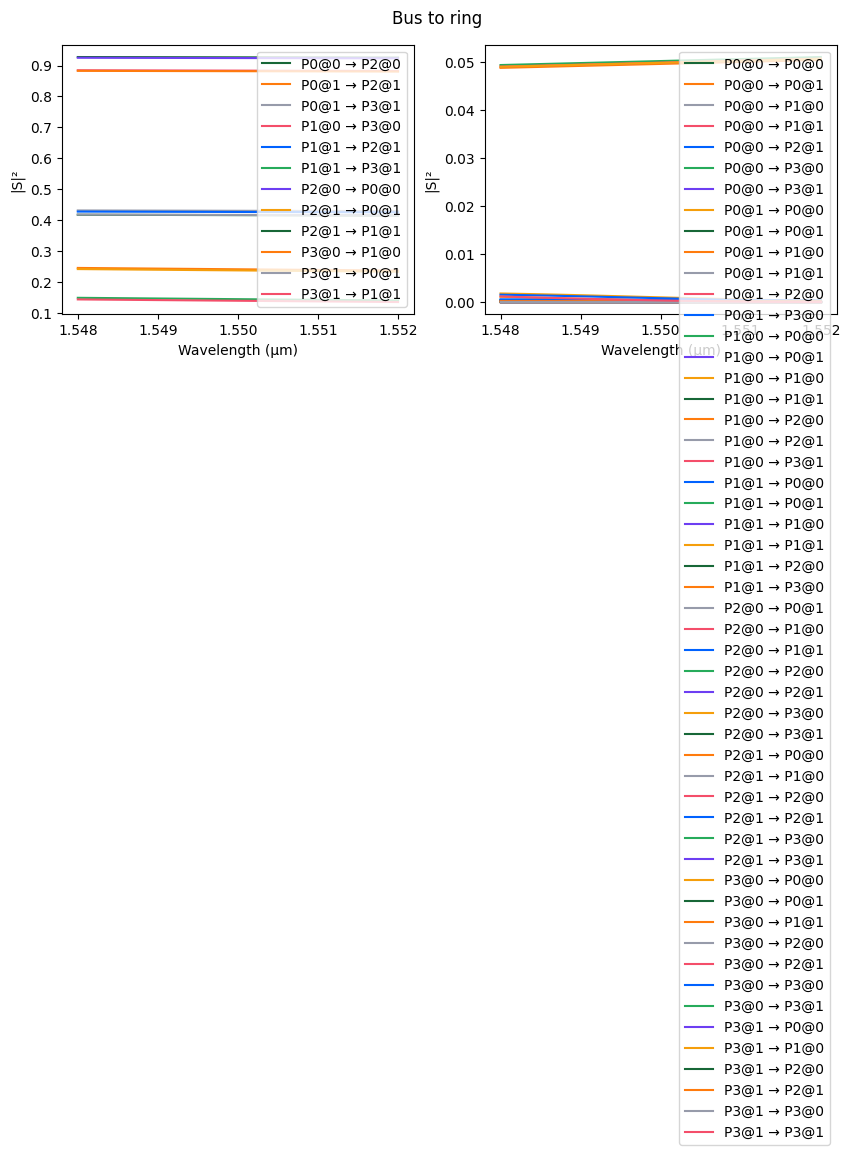

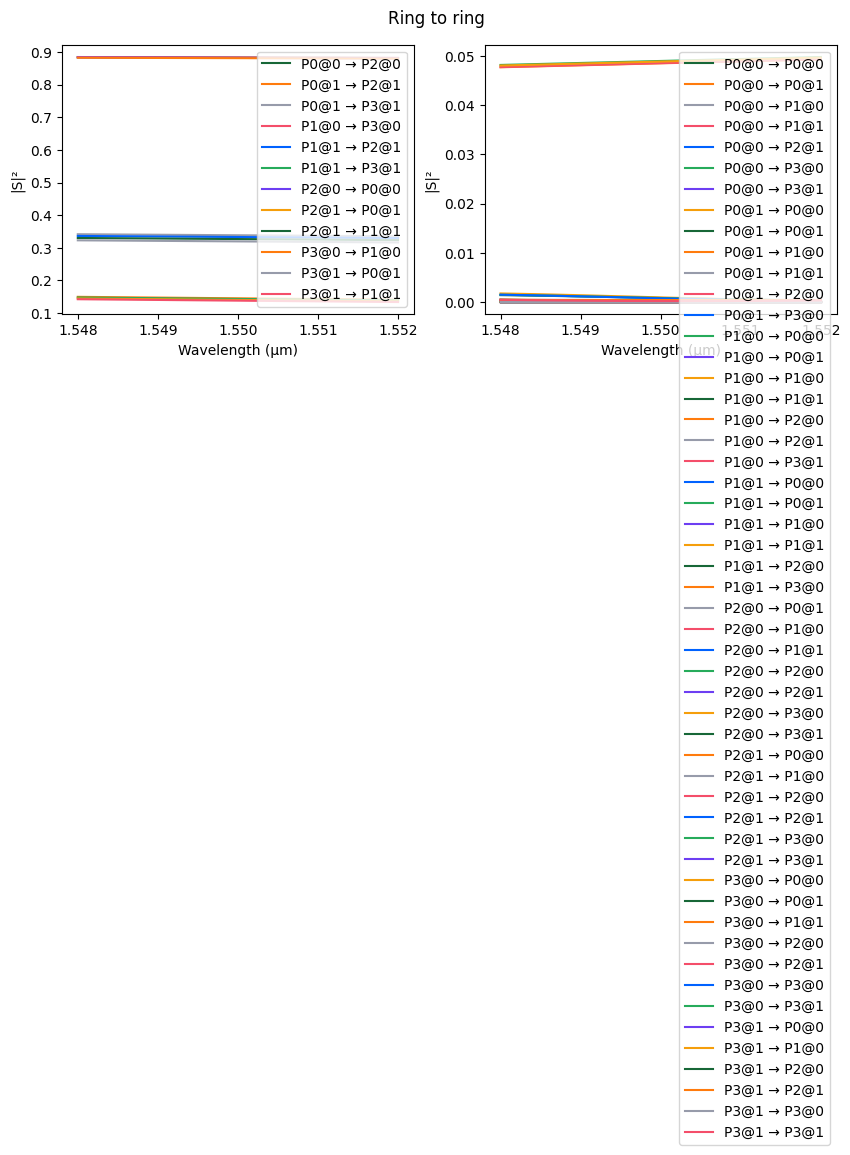

In [13]:
if run_fdtd:
    fig, _ = pf.plot_s_matrix(bus_to_ring.s_matrix(pf.C_0 / wavelengths))
    fig.suptitle("Bus to ring")

    fig, _ = pf.plot_s_matrix(ring_to_ring.s_matrix(pf.C_0 / wavelengths))
    _ = fig.suptitle("Ring to ring")

## Add drop filter

Now that we have simulated S parameters for the point couplers, we use a netlist-driven layout to create an add-drop filter and look at the resonant response of the ring.
The [component_from_netlist](../_autosummary/photonforge.component_from_netlist.rst) function can be used to build an add-drop filter component with a [circuit model](../_autosummary/photonforge.CircuitModel.rst).

In [6]:
netlist_add_drop = {
    "name": "add_drop",
    "instances": [bus_to_ring, bus_to_ring],
    "connections": [((1, "P1"), (0, "P3"))],
    "ports": [
        (0, "P0", "In"),
        (0, "P2", "Through"),
        (1, "P0", "Add"),
        (1, "P2", "Drop"),
    ],
    "models": [pf.CircuitModel()],
}

add_drop = pf.component_from_netlist(netlist_add_drop)
add_drop

Since we have added a Circuit model to the add-drop filter, PhotonForge automatically uses the S parameters that were already calculated for the instance components to calculate the circuit's S matrix.
It will need to perform a few mode-solver calculations to make sure the correct phases are accounted for after instance rotations.

18:39:52 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=389862;https://tidy3d.simulation.cloud/workbench?taskId=mo-70b9094e-aaf7-46f6-9705-876996b27675\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=181745;https://tidy3d.simulation.cloud/workbench?taskId=mo-70b9094e-aaf7-46f6-9705-876996b27675\taskId]8;;\]8;id=389862;https://tidy3d.simulation.cloud/workbench?taskId=mo-70b9094e-aaf7-46f6-9705-876996b27675\=]8;;\]8;id=385248;https://tidy3d.simulation.cloud/workbench?taskId=mo-70b9094e-aaf7-46f6-9705-876996b27675\mo]8;;\]8;id=389862;https://tidy3d.simulation.cloud/workbench?taskId=mo-70b9094e-aaf7-46f6-9705-876996b27675\-70b9094e-aaf7-]8;;\
             ]8;id=389862;https://tidy3d.simulation.cloud/workbench?taskId=mo-70b9094e-aaf7-46f6-9705-876996b27675\46f6-9705-876996b27675']8;;\.

18:39:53 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=231017;https://tidy3d.simulation.cloud/workbench?taskId=mo-d51d31d3-a71d-4dcc-8f53-45ca76d324db\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=780057;https://tidy3d.simulation.cloud/workbench?taskId=mo-d51d31d3-a71d-4dcc-8f53-45ca76d324db\taskId]8;;\]8;id=231017;https://tidy3d.simulation.cloud/workbench?taskId=mo-d51d31d3-a71d-4dcc-8f53-45ca76d324db\=]8;;\]8;id=77992;https://tidy3d.simulation.cloud/workbench?taskId=mo-d51d31d3-a71d-4dcc-8f53-45ca76d324db\mo]8;;\]8;id=231017;https://tidy3d.simulation.cloud/workbench?taskId=mo-d51d31d3-a71d-4dcc-8f53-45ca76d324db\-d51d31d3-a71d-]8;;\
             ]8;id=231017;https://tidy3d.simulation.cloud/workbench?taskId=mo-d51d31d3-a71d-4dcc-8f53-45ca76d324db\4dcc-8f53-45ca76d324db']8;;\.

18:39:54 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=626223;https://tidy3d.simulation.cloud/workbench?taskId=mo-9160e41e-294b-4a80-8528-a3d9f12c1a38\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=661650;https://tidy3d.simulation.cloud/workbench?taskId=mo-9160e41e-294b-4a80-8528-a3d9f12c1a38\taskId]8;;\]8;id=626223;https://tidy3d.simulation.cloud/workbench?taskId=mo-9160e41e-294b-4a80-8528-a3d9f12c1a38\=]8;;\]8;id=442409;https://tidy3d.simulation.cloud/workbench?taskId=mo-9160e41e-294b-4a80-8528-a3d9f12c1a38\mo]8;;\]8;id=626223;https://tidy3d.simulation.cloud/workbench?taskId=mo-9160e41e-294b-4a80-8528-a3d9f12c1a38\-9160e41e-294b-]8;;\
             ]8;id=626223;https://tidy3d.simulation.cloud/workbench?taskId=mo-9160e41e-294b-4a80-8528-a3d9f12c1a38\4a80-8528-a3d9f12c1a38']8;;\.

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=460941;https://tidy3d.simulation.cloud/workbench?taskId=mo-3cdf8451-ba55-4f9b-b994-d217f2743c0b\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=858634;https://tidy3d.simulation.cloud/workbench?taskId=mo-3cdf8451-ba55-4f9b-b994-d217f2743c0b\taskId]8;;\]8;id=460941;https://tidy3d.simulation.cloud/workbench?taskId=mo-3cdf8451-ba55-4f9b-b994-d217f2743c0b\=]8;;\]8;id=876188;https://tidy3d.simulation.cloud/workbench?taskId=mo-3cdf8451-ba55-4f9b-b994-d217f2743c0b\mo]8;;\]8;id=460941;https://tidy3d.simulation.cloud/workbench?taskId=mo-3cdf8451-ba55-4f9b-b994-d217f2743c0b\-3cdf8451-ba55-]8;;\
             ]8;id=460941;https://tidy3d.simulation.cloud/workbench?taskId=mo-3cdf8451-ba55-4f9b-b994-d217f2743c0b\4f9b-b994-d217f2743c0b']8;;\.

Progress: 100% 


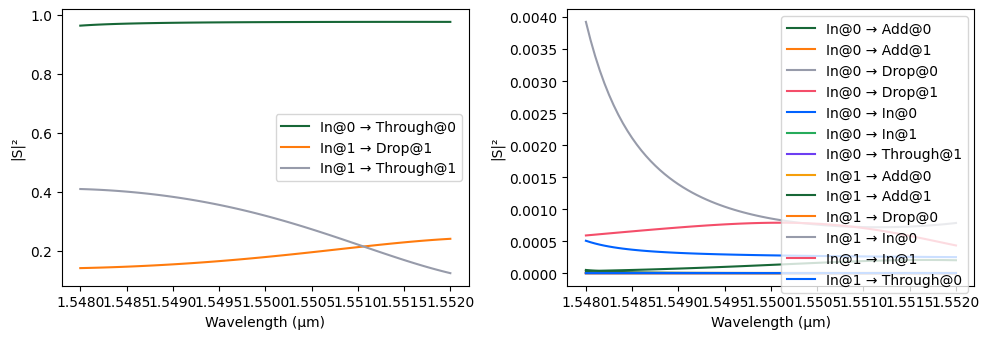

In [15]:
if run_fdtd:
    s_matrix_add_drop = add_drop.s_matrix(frequencies=pf.C_0 / wavelengths)
    _ = pf.plot_s_matrix(s_matrix_add_drop, input_ports=["In"])

## Coupled Rings

Next, we can create a coupled-ring filter to see the effect of cascading identical resonators.
Again, we will use netlist helper to create the component. 

In [7]:
netlist_coupled_rings = {
    "name": "cascaded_ring_filter",
    "instances": {
        "bus_coupler0": bus_to_ring,
        "bus_coupler1": bus_to_ring,
        "ring_coupler0": ring_to_ring,
        "ring_coupler1": ring_to_ring,
    },
    "connections": [
        (("ring_coupler0", "P0"), ("bus_coupler0", "P1")),
        (("ring_coupler1", "P0"), ("ring_coupler0", "P1")),
        (("bus_coupler1", "P3"), ("ring_coupler1", "P1")),
    ],
    "ports": [
        ("bus_coupler0", "P0", "In"),
        ("bus_coupler1", "P2", "Drop"),
        ("bus_coupler0", "P2", "Through"),
        ("bus_coupler1", "P0", "Add"),
    ],
    "models": [pf.CircuitModel()],
}


coupled_rings = pf.component_from_netlist(netlist_coupled_rings)
coupled_rings

Progress: 100% 


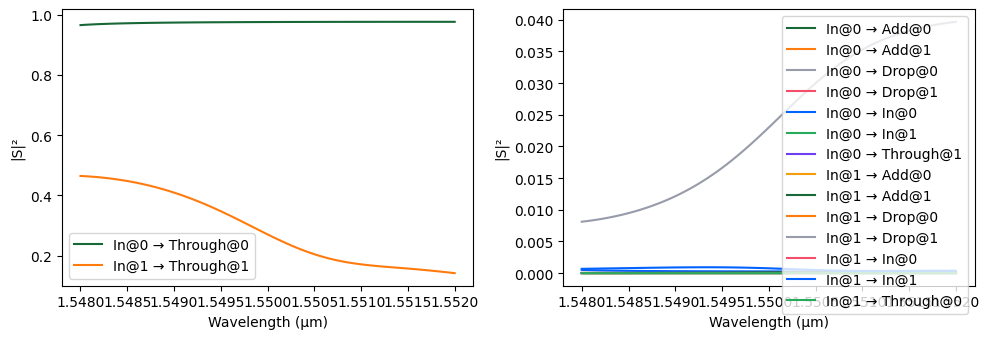

In [17]:
if run_fdtd:
    s_matrix_coupled_rings = coupled_rings.s_matrix(frequencies=pf.C_0 / wavelengths)
    _ = pf.plot_s_matrix(s_matrix_coupled_rings, input_ports=["In"])

We can see how it is possible to change the filter response not just at the pass band but also modify it to achieve a sharp roll-off in the rejection band.

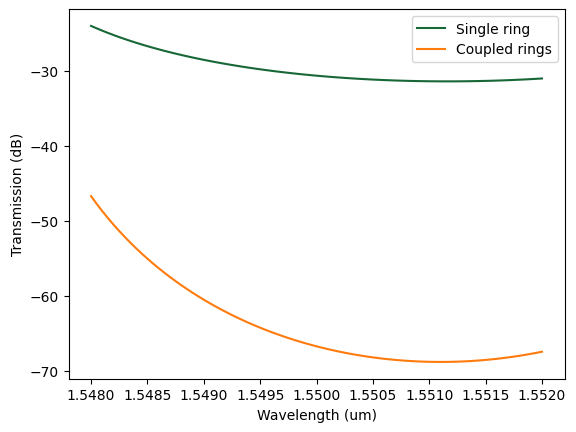

In [18]:
if run_fdtd:
    plt.plot(
        wavelengths,
        20 * np.log10(np.abs(s_matrix_add_drop[(f"In@0", f"Drop@0")])),
        label=f"Single ring",
    )
    plt.plot(
        wavelengths,
        20 * np.log10(np.abs(s_matrix_coupled_rings[(f"In@0", f"Drop@0")])),
        label=f"Coupled rings",
    )
    plt.xlabel("Wavelength (um)")
    plt.ylabel("Transmission (dB)")
    _ = plt.legend()

## Cascaded add-drop filters

Another common configuration is to cascade the rings in series in the same bus waveguide, possibly with slightly different resonant frequencies.
We will use a termination on one of the add/drop filter ports and connect a routing waveguide bend to the other, which can be used to connect to other parts of the circuit later.

We start by creating the termination (from scratch) and the bend (using a parametric component):


In [8]:
termination = pf.Component("Termination")
termination.add("wg_lf", pf.stencil.linear_taper(20, (0.5, 0.1)))
termination.add_port(pf.Port((0, 0), 0, port_spec))
termination.add_model(pf.Tidy3DModel())
termination

In [9]:
bend = pf.parametric.bend(name="Bend")
bend

Now we create the terminated single add/drop filter as a parametric component, using an extra straight section in the ring to change the resonant frequency.
Because of the simplicity of this component, we can still use a netlist-driven design.

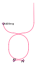

In [10]:
@pf.parametric_component
def create_add_drop(*, added_length=0):
    # Basic add-drop filter netlist
    netlist = {
        "instances": {
            "bus_coupler0": bus_to_ring,
            "bus_coupler1": bus_to_ring,
            "bend0": bend,
            "bend1": bend,
            "termination": termination,
        },
        "connections": [
            (("bus_coupler1", "P1"), ("bus_coupler0", "P3")),
            (("bend1", "P0"), ("bus_coupler1", "P0")),
            (("termination", "P0"), ("bend1", "P1")),
            (("bend0", "P1"), ("bus_coupler1", "P2")),
        ],
        "ports": [
            ("bus_coupler0", "P0"),
            ("bus_coupler0", "P2"),
            ("bend0", "P0", "Add/Drop"),
        ],
        "models": [pf.CircuitModel()],
    }

    if added_length > 0:
        # If we need extra length, add 2 spacer instances to the netlist and
        # re-connect the instances appropriately
        spacer = pf.parametric.straight(length=added_length)
        netlist["instances"]["spacer0"] = spacer
        netlist["instances"]["spacer1"] = spacer

        netlist["connections"] = [
            (("spacer0", "P0"), ("bus_coupler0", "P1")),
            (("spacer1", "P1"), ("bus_coupler0", "P3")),
            (("bus_coupler1", "P1"), ("spacer1", "P0")),
            (("bend1", "P0"), ("bus_coupler1", "P0")),
            (("termination", "P0"), ("bend1", "P1")),
            (("bend0", "P1"), ("bus_coupler1", "P2")),
        ]
    return pf.component_from_netlist(netlist)


create_add_drop(added_length=5)

We connect 3 terminated rings with an appropriate spacer between them.
Each ring has a different resonance.

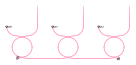

In [11]:
spacer = pf.parametric.straight(name="spacer", length=35)

netlist_cascaded_rings = {
    "name": "filter_circuit",
    "instances": {
        "AD0": create_add_drop(added_length=0.005),
        "AD1": create_add_drop(added_length=0.015),
        "AD2": create_add_drop(added_length=0.025),
        "SP1": spacer,
        "SP2": spacer,
    },
    "connections": [
        (("SP1", "P0"), ("AD0", "P1")),
        (("AD1", "P0"), ("SP1", "P1")),
        (("SP2", "P0"), ("AD1", "P1")),
        (("AD2", "P0"), ("SP2", "P1")),
    ],
    "ports": [
        ("AD0", "P0"),
        ("AD2", "P1"),
        ("AD0", "Add/Drop", "AD0"),
        ("AD1", "Add/Drop", "AD1"),
        ("AD2", "Add/Drop", "AD2"),
    ],
    "models": [pf.CircuitModel()],
}

cascaded_rings = pf.component_from_netlist(netlist_cascaded_rings)
cascaded_rings

18:40:18 BST Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=998384;https://tidy3d.simulation.cloud/workbench?taskId=mo-13f62fa8-6db9-470a-9e82-f2ffe4f4404a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=744199;https://tidy3d.simulation.cloud/workbench?taskId=mo-13f62fa8-6db9-470a-9e82-f2ffe4f4404a\taskId]8;;\]8;id=998384;https://tidy3d.simulation.cloud/workbench?taskId=mo-13f62fa8-6db9-470a-9e82-f2ffe4f4404a\=]8;;\]8;id=191190;https://tidy3d.simulation.cloud/workbench?taskId=mo-13f62fa8-6db9-470a-9e82-f2ffe4f4404a\mo]8;;\]8;id=998384;https://tidy3d.simulation.cloud/workbench?taskId=mo-13f62fa8-6db9-470a-9e82-f2ffe4f4404a\-13f62fa8-6db9-]8;;\
             ]8;id=998384;https://tidy3d.simulation.cloud/workbench?taskId=mo-13f62fa8-6db9-470a-9e82-f2ffe4f4404a\470a-9e82-f2ffe4f4404a']8;;\.

18:40:20 BST WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 3 WARNING messages.                            

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 3 WARNING messages.                            

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=94592;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f49303eb-bb46-47d1-8529-10573cd9e28c\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=707294;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f49303eb-bb46-47d1-8529-10573cd9e28c\taskId]8;;\]8;id=94592;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f49303eb-bb46-47d1-8529-10573cd9e28c\=]8;;\]8;id=690102;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f49303eb-bb46-47d1-8529-10573cd9e28c\fdve]8;;\]8;id=94592;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f49303eb-bb46-47d1-8529-10573cd9e28c\-f49303eb-bb4]8;;\
             ]8;id=94592;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f49303eb-bb46-47d1-8529-10573cd9e28c\6-47d1-8529-10573cd9e28c']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 3 WARNING messages.                            

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

             Loading simulation from local cache. View cached task using web UI 
             at                                                                 
             ]8;id=851518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2c325c03-9e00-4ab9-8f7a-f85a3d805718\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=495139;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2c325c03-9e00-4ab9-8f7a-f85a3d805718\taskId]8;;\]8;id=851518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2c325c03-9e00-4ab9-8f7a-f85a3d805718\=]8;;\]8;id=844936;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2c325c03-9e00-4ab9-8f7a-f85a3d805718\fdve]8;;\]8;id=851518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2c325c03-9e00-4ab9-8f7a-f85a3d805718\-2c325c03-9e0]8;;\
             ]8;id=851518;https://tidy3d.simulation.cloud/workbench?taskId=fdve-2c325c03-9e00-4ab9-8f7a-f85a3d805718\0-4ab9-8f7a-f85a3d805718']8;;\.

             WARNING: Structure at 'structures[0]' has bounds that extend       
             exactly to simulation edges. This can cause unexpected behavior. If
             intending to extend the structure to infinity along one dimension, 
             use td.inf as a size variable instead to make this explicit.       

             WARNING: Suppressed 3 WARNING messages.                            

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

Progress: 100% 


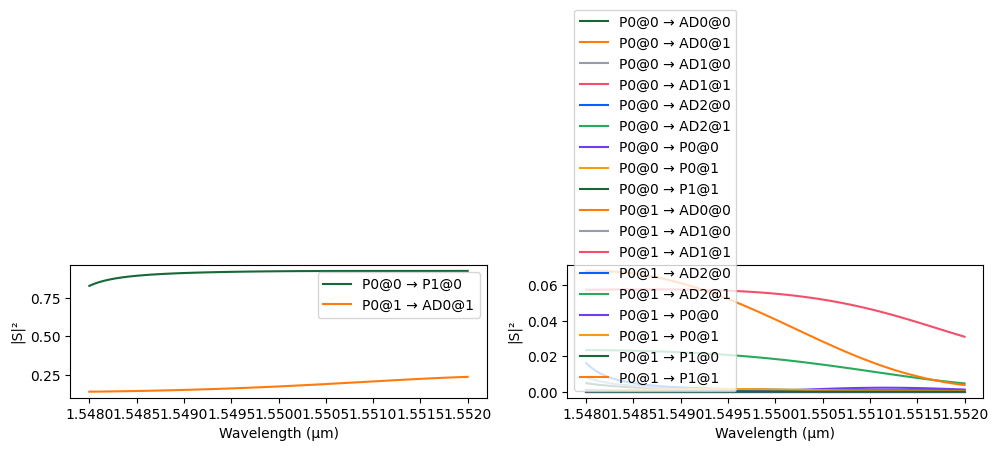

In [23]:
if run_fdtd:
    _ = pf.plot_s_matrix(cascaded_rings.s_matrix(pf.C_0 / wavelengths), input_ports=["P0"])

The warnings can be safely ignored in this case, because our waveguides don't really end at the boundaries, but continue through the absorbing layers through adjacent structures.

## Complete Design

Finally, we will include [grating couplers](Grating_Coupler.ipynb) to the cascaded filter that can be used to couple light into and out of the chip.
The Cornerstone PDK already provides a grating designed for the port specification we chose, so we don't have to design it from scratch:

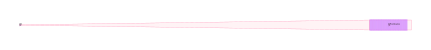

In [12]:
grating_coupler = pdk.component("SOI220nm_1550nm_TE_STRIP_Grating_Coupler")
grating_coupler

The grating can be easily simulated in Tidy3D just as we did with other components, but because of its size, we will demonstrate the flexibility in PhotonForge to use pre-computed or experimental data from Touchstone files using a [data model](../guides/Data_Model.ipynb).

In order to facilitate the distribution of this example, the file data is embedded here, so we will first write it to a file (this data file would have been provided by previous computations or experiments).

In [18]:
print(grating_coupler.active_model)

DataModel


Progress: 100% 


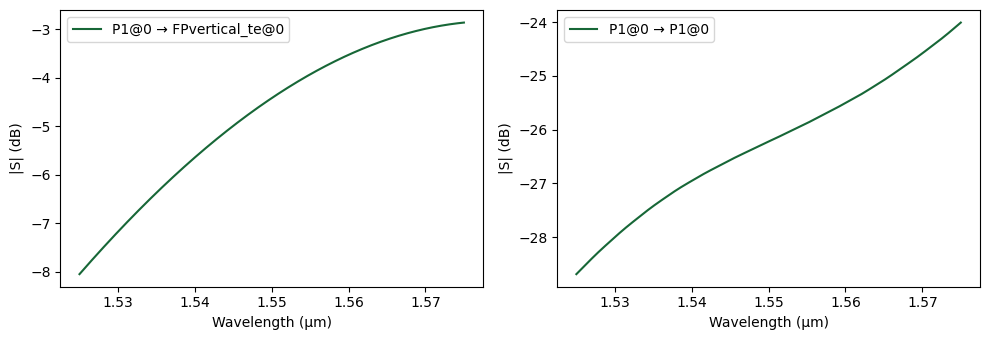

In [26]:
wavelengths_dense = np.linspace(1.525, 1.575, 1001)

_ = pf.plot_s_matrix(
    grating_coupler.s_matrix(pf.C_0 / wavelengths_dense), y="dB", input_ports=["P1"]
)

In [13]:
netlist_layout = {
    "name": "main",
    "instances": {
        "filter": cascaded_rings,
        "grating0": grating_coupler,
        "grating1": grating_coupler,
        "spacer0": spacer,
        "spacer1": spacer,
    },
    "connections": [
        (("spacer0", "P0"), ("grating0", "P1")),
        (("filter", "P0"), ("spacer0", "P1")),
        (("spacer1", "P0"), ("filter", "P1")),
        (("grating1", "P1"), ("spacer1", "P1")),
    ],
    "ports": [
        ("grating0", "FPvertical_TE"),
        ("grating1", "FPvertical_TE"),
        ("filter", "AD0"),
        ("filter", "AD1"),
        ("filter", "AD2"),
    ],
    "models": [pf.CircuitModel()],
}

layout = pf.component_from_netlist(netlist_layout)

# layout.write_gds("cascaded_rings.gds")

Once again, we can simulate our full device, but now with a denser and wider wavelength grid to verify the full transmission spectrum between grating couplers.
Note that this simulation may take a little longer because we are calculating modes using a fine frequency sweep.

In [ ]:
if run_fdtd:
    wavelengths_wide = np.linspace(1.525, 1.575, 501)
    s_layout = layout.s_matrix(frequencies=pf.C_0 / wavelengths_wide)

: 

In [ ]:
if run_fdtd:
    _, ax = plt.subplots(1, 1, figsize=(9, 3))
    ax.plot(wavelengths_wide, 20 * np.log10(np.abs(s_layout["P0@0", "P1@0"])))
    _ = ax.set(xlabel="Wavelength (μm)", ylabel="Transmission (dB)", ylim=(-30, None))

We see that overall filter response has a spectral dependence due to the wavelength response of the grating.

## Testing Variations

The Circuit model allows us to test the effect of parameter changes in technologies, components, and models in specific references through the `updates` keyword argument available in the Circuit model's [start](../_autosummary/photonforge.CircuitModel.rst#photonforge.CircuitModel.start) method.

In this case we want to see the effect of changing the resonance frequency of each ring in the filter circuit by modifying the added lengths in each of them.
For that, we set a dictionary of updates that first matches each add/drop filter by name (`"create_add_drop_…"`) at any depth of the dependency tree (the value `None` in the reference specification tuple indicates that whatever follows ca match at any depth).
Within each add/drop filter, we select references whose component name starts with "straight" using a regular expression (`.*` will match any suffix), and, finally, update the model of those components (which are [Waveguide models](../_autosummary/photonforge.WaveguideModel.rst)) with a new length parameter.

In [ ]:
if run_fdtd:
    updates = {
        (None, "create_add_drop_added_length_0_005", "straight.*"): {"model_updates": {"length": 0.0}},
        (None, "create_add_drop_added_length_0_015", "straight.*"): {"model_updates": {"length": 0.02}},
        (None, "create_add_drop_added_length_0_025", "straight.*"): {"model_updates": {"length": 0.06}},
    }
    updated_s_matrix = layout.s_matrix(
        pf.C_0 / wavelengths_wide, model_kwargs={"updates": updates}
    )

    _, ax = plt.subplots(1, 1, figsize=(9, 3))
    ax.plot(wavelengths_wide, 20 * np.log10(np.abs(updated_s_matrix["P0@0", "P1@0"])))
    _ = ax.set(xlabel="Wavelength (μm)", ylabel="Transmission (dB)", ylim=(-30, None))

Because we created each add/drop filter as a parametric component with the `added_length` parameter, we could also obtain the same result by updating the component themselves:

In [ ]:
if run_fdtd:
    updates = {
        (None, "create_add_drop_added_length_0_005"): {"component_updates": {"added_length": 0.0}},
        (None, "create_add_drop_added_length_0_015"): {"component_updates": {"added_length": 0.02}},
        (None, "create_add_drop_added_length_0_025"): {"component_updates": {"added_length": 0.06}},
    }
    updated_s_matrix = layout.s_matrix(
        pf.C_0 / wavelengths_wide, model_kwargs={"updates": updates}
    )

    _, ax = plt.subplots(1, 1, figsize=(9, 3))
    ax.plot(wavelengths_wide, 20 * np.log10(np.abs(updated_s_matrix["P0@0", "P1@0"])))
    _ = ax.set(xlabel="Wavelength (μm)", ylabel="Transmission (dB)", ylim=(-30, None))